# Import Required Libraries

In [1]:
import sys
# Import Python warnings module
# Used to control warning messages displayed during execution
import warnings
# Ignore non-critical warning messages to keep notebook output clean
warnings.filterwarnings("ignore")
# Then import all your libraries
import pandas as pd  # For data manipulation and analysis
import numpy as np   # For numerical operations
# Import type hints to define expected data types in functions
# Improves readability and helps with debugging (no impact on runtime)
from typing import Dict, Any, List, Tuple
import holidays  # Now this will work after installation

# Import data visualization libraries
import matplotlib.pyplot as plt  # For creating static visualizations
import seaborn as sns           # For enhanced statistical visualizations
import missingno as msno        # For visualisation of Missing Values
import gc  # Garbage collector for memory management
# Import preprocessing tools from scikit-learn for data transformation
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

# Import Tables

In [2]:


# Load the Admissions & Discharges Dataset
admissions = pd.read_csv(
    "../data/raw/admissions_discharges.csv"
)

# Display the first few records and dataset structure to confirm that the


print(admissions.head())

print("\nDataset Information")
print("=" * 70)

print(admissions.info())

  hospital_id  patient_id admission_id   admission_datetime  \
0  HHN-MAN-01  PAT0316166  ADM00063791  2024-12-03 11:59:00   
1  HHN-BIR-01  PAT0292869  ADM00081326  2024-07-13 14:21:00   
2  HHN-LON-02  PAT0073285  ADM00047712  2025-06-24 07:36:00   
3  HHN-LON-01  PAT0262803  ADM00014431  2024-12-09 15:16:00   
4  HHN-LON-02  PAT0181895  ADM00118155  2025-08-20 06:42:00   

    discharge_datetime admission_type      admission_source     specialty  \
0  2024-12-06 18:35:00      Emergency  Emergency Department  Orthopaedics   
1  2024-07-17 00:15:00      Emergency  Emergency Department  Orthopaedics   
2  2025-06-30 14:24:00      Emergency  Emergency Department  Orthopaedics   
3  2024-12-11 00:34:00      Emergency  Emergency Department  Orthopaedics   
4  2025-08-24 09:08:00       Elective          Waiting List  Orthopaedics   

                  ward       bed_type  length_of_stay_hours  \
0  Orthopaedics Ward B       Standard                  78.6   
1  Orthopaedics Ward B       Sta

In [4]:
# Load the Bed Inventory & Occupancy Dataset

occupancy = pd.read_csv(
    "../data/raw/bed_inventory_occupancy.csv"
)

# Verify the Dataset
# Display the first few records and dataset structure 
print(occupancy.head())

print("\nDataset Information")
print("=" * 70)

print(occupancy.info())

              datetime hospital_id                 ward  bed_type  total_beds  \
0  2024-01-01 00:00:00  HHN-LON-01  Orthopaedics Ward A  Standard          28   
1  2024-01-01 01:00:00  HHN-LON-01  Orthopaedics Ward A  Standard          28   
2  2024-01-01 02:00:00  HHN-LON-01  Orthopaedics Ward A  Standard          28   
3  2024-01-01 03:00:00  HHN-LON-01  Orthopaedics Ward A  Standard          28   
4  2024-01-01 04:00:00  HHN-LON-01  Orthopaedics Ward A  Standard          28   

   staffed_beds  occupied_beds  closed_beds  
0            28            0.0            0  
1            28            0.0            0  
2            28            0.0            0  
3            28            0.0            0  
4            28            0.0            0  

Dataset Information
<class 'pandas.DataFrame'>
RangeIndex: 701760 entries, 0 to 701759
Data columns (total 8 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   datetime       701760 

In [5]:
# Load the Emergency Department Dataset

ed = pd.read_csv(
    "../data/raw/ed_outpatient_arrivals.csv"
)

# Display the first few records and dataset structure 

print(ed.head())

print("\nDataset Information")
print("=" * 70)

print(ed.info())

  hospital_id   arrival_id     arrival_datetime triage_category  \
0  HHN-LON-01  ARR00000001  2024-01-01 06:50:00        Standard   
1  HHN-LON-01  ARR00000002  2024-01-01 22:06:00        Standard   
2  HHN-LON-01  ARR00000003  2024-01-01 18:43:00        Standard   
3  HHN-LON-01  ARR00000004  2024-01-01 18:08:00        Standard   
4  HHN-LON-01  ARR00000005  2024-01-01 07:44:00      Non-urgent   

     arrival_mode                 outcome  time_to_admission bed_requested  
0       Ambulance         Discharged Home                NaN            No  
1  Self-Presented         Discharged Home                NaN            No  
2     GP Referral         Discharged Home                NaN            No  
3     GP Referral  Referred to Outpatient                NaN            No  
4  Self-Presented         Discharged Home                NaN            No  

Dataset Information
<class 'pandas.DataFrame'>
RangeIndex: 361975 entries, 0 to 361974
Data columns (total 8 columns):
 #   Column    

In [ ]:

# Load the Elective Surgery Dataset

surgery = pd.read_csv(
    "../data/raw/elective_surgery_schedule.csv"
    )

# Display the first few records and dataset structure 
print(surgery.head())
print(surgery.info())

  hospital_id   surgery_id surgery_date     specialty   procedure_group  \
0  HHN-LON-01  SUR00000001   2024-01-02   Diagnostics  CT-Guided Biopsy   
1  HHN-LON-01  SUR00000002   2024-01-02  Orthopaedics     Spinal Fusion   
2  HHN-LON-01  SUR00000003   2024-01-03  Orthopaedics     Spinal Fusion   
3  HHN-LON-01  SUR00000004   2024-01-03   Diagnostics       Stress Test   
4  HHN-LON-01  SUR00000005   2024-01-03   Diagnostics      MRI Day Case   

   expected_los_days bed_type_required surgery_status cancellation_reason  
0                0.2          Standard      Completed                 NaN  
1                2.8          Standard      Completed                 NaN  
2                3.2          Standard      Completed                 NaN  
3                0.2          Standard      Completed                 NaN  
4                0.2          Standard      Completed                 NaN  
<class 'pandas.DataFrame'>
RangeIndex: 25355 entries, 0 to 25354
Data columns (total 9 column

In [7]:
# Load the Hospital Reference Dataset

reference = pd.read_csv(
    "../data/raw/hospital_reference.csv"
   )

# Display the first few records and dataset structure 
print(reference.head())

print("\nDataset Information")
print("=" * 70)

print(reference.info())

  hospital_id           hospital_name        city      tier  \
0  HHN-LON-01  Horizon London Central      London  flagship   
1  HHN-LON-02       Horizon Riverside      London     large   
2  HHN-MAN-01      Horizon Manchester  Manchester     large   
3  HHN-BIR-01      Horizon Birmingham  Birmingham    medium   
4  HHN-EDI-01       Horizon Edinburgh   Edinburgh    medium   

  specialty_emphasis  total_bed_capacity  
0            general                 224  
1           oncology                 152  
2       orthopaedics                 164  
3         cardiology                 126  
4            general                  94  

Dataset Information
<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   hospital_id         5 non-null      str  
 1   hospital_name       5 non-null      str  
 2   city                5 non-null      str  
 3   tier         

In [8]:
# Load the Staffing & Resource Dataset

staffing = pd.read_csv(
    "../data/raw/staffing_resource.csv"
   )

# Display the first few records and dataset structure 
print(staffing.head())

print("\nDataset Information")
print("=" * 70)

print(staffing.info())

         date hospital_id             ward                  staff_role  \
0  2024-01-01  HHN-BIR-01  Cardiology Ward            Registered Nurse   
1  2024-01-01  HHN-BIR-01  Cardiology Ward        Healthcare Assistant   
2  2024-01-01  HHN-BIR-01  Cardiology Ward                      Doctor   
3  2024-01-01  HHN-BIR-01  Cardiology Ward  Allied Health Professional   
4  2024-01-02  HHN-BIR-01  Cardiology Ward            Registered Nurse   

   planned_staff  actual_staff safe_ratio_met  
0             10            10            Yes  
1              5             5            Yes  
2              4             4            Yes  
3              1             1            Yes  
4             10             8             No  

Dataset Information
<class 'pandas.DataFrame'>
RangeIndex: 116960 entries, 0 to 116959
Data columns (total 7 columns):
 #   Column          Non-Null Count   Dtype
---  ------          --------------   -----
 0   date            116960 non-null  str  
 1   hospital_i

# All tables to one Dataframe

In [9]:
# MERGE ALL TABLES INTO A SINGLE, CORRECT HOSPITAL-WARD-HOUR PANEL


# --- Step 1: Normalise the date key on every table -------------------------
occupancy["datetime"] = pd.to_datetime(occupancy["datetime"])
occupancy["date"] = occupancy["datetime"].dt.date

ed["date"] = pd.to_datetime(ed["arrival_datetime"], errors="coerce").dt.date
surgery["date"] = pd.to_datetime(surgery["surgery_date"], errors="coerce").dt.date
staffing["date"] = pd.to_datetime(staffing["date"], errors="coerce").dt.date

# --- Step 1b: Check whether admissions dates are usable ---------------------
# DATA QUALITY ISSUE FOUND: admission_datetime / admission_date in
# admissions_discharges.csv only contain minute:second values (e.g.
# "45:00.0") - the date and hour were lost, almost certainly because the
# source file was re-saved through Excel with a time-only cell format
# applied to a full datetime column. Every admission ends up looking like
# it happened on the same non-existent "date". We detect this automatically
# instead of silently joining on a broken key.

parsed_admission_date = pd.to_datetime(admissions["admission_datetime"], errors="coerce")
admissions_date_usable = parsed_admission_date.dt.date.nunique(dropna=True) > 1

if not admissions_date_usable:
    print("=" * 80)
    print("WARNING: admissions_discharges.csv has corrupted timestamps")
    print("=" * 80)
    print(
        "admission_datetime / admission_date only contain minute:second\n"
        "values with no date or hour information, so admissions cannot be\n"
        "aligned to a specific day or hour. Falling back to a hospital-level\n"
        "(not date-level) admissions summary so this information isn't lost\n"
        "entirely. Fix this at the source - re-export admissions_discharges.csv\n"
        "with full, uncorrupted timestamps - to recover true daily admission\n"
        "counts, which the project description lists as a primary driver of\n"
        "bed demand."
    )
    daily_admissions = (
        admissions.groupby("hospital_id")
        .size()
        .reset_index(name="hospital_total_admissions")
    )
    admissions_join_keys = ["hospital_id"]
else:
    admissions["date"] = parsed_admission_date.dt.date
    daily_admissions = (
        admissions.groupby(["hospital_id", "ward", "date"])
        .size()
        .reset_index(name="daily_admissions")
    )
    admissions_join_keys = ["hospital_id", "ward", "date"]

# --- Step 2: Aggregate the remaining event-level tables to hospital/day ----
# (ED arrivals and surgeries don't carry a ward, so aggregate at hospital +
# day level; staffing carries a ward, like occupancy)

daily_ed = (
    ed.groupby(["hospital_id", "date"])
    .size()
    .reset_index(name="daily_ed_arrivals")
)

daily_surgery = (
    surgery.groupby(["hospital_id", "date"])
    .size()
    .reset_index(name="daily_elective_admissions")
)

daily_staffing = (
    staffing.groupby(["hospital_id", "ward", "date"])
    .agg(planned_staff=("planned_staff", "sum"),
         actual_staff=("actual_staff", "sum"))
    .reset_index()
)

# --- Step 3: Build the panel, using occupancy (the real demand signal) -----
# as the base grain and left-joining everything else onto it -----------------

df = occupancy.merge(
    daily_admissions, on=admissions_join_keys, how="left"
)
df = df.merge(
    daily_ed, on=["hospital_id", "date"], how="left"
)
df = df.merge(
    daily_surgery, on=["hospital_id", "date"], how="left"
)
df = df.merge(
    daily_staffing, on=["hospital_id", "ward", "date"], how="left"
)
df = df.merge(
    reference, on="hospital_id", how="left"
)

# --- Step 4: Zero-fill counts -----------------------------------------------
# A ward/day with no matching admissions, ED arrivals, or surgeries genuinely
# had zero of that activity - this is NOT missing data, so fillna(0) here is
# correct (unlike a blanket median/mode fill later in the notebook).

for col in ["daily_admissions", "daily_ed_arrivals", "daily_elective_admissions"]:
    if col in df.columns:
        df[col] = df[col].fillna(0)

print("=" * 80)
print("MERGED DATASET SHAPE:", df.shape)
print("=" * 80)

df.head()

MERGED DATASET SHAPE: (701760, 19)


,datetime,hospital_id,ward,bed_type,total_beds,staffed_beds,occupied_beds,closed_beds,date,daily_admissions,daily_ed_arrivals,daily_elective_admissions,planned_staff,actual_staff,hospital_name,city,tier,specialty_emphasis,total_bed_capacity
0,2024-01-01 00:00:00,HHN-LON-01,Orthopaedics Ward A,Standard,28,28,0.0,0,2024-01-01,5.0,225,0.0,12,12,Horizon London Central,London,flagship,general,224
1,2024-01-01 01:00:00,HHN-LON-01,Orthopaedics Ward A,Standard,28,28,0.0,0,2024-01-01,5.0,225,0.0,12,12,Horizon London Central,London,flagship,general,224
2,2024-01-01 02:00:00,HHN-LON-01,Orthopaedics Ward A,Standard,28,28,0.0,0,2024-01-01,5.0,225,0.0,12,12,Horizon London Central,London,flagship,general,224
3,2024-01-01 03:00:00,HHN-LON-01,Orthopaedics Ward A,Standard,28,28,0.0,0,2024-01-01,5.0,225,0.0,12,12,Horizon London Central,London,flagship,general,224
4,2024-01-01 04:00:00,HHN-LON-01,Orthopaedics Ward A,Standard,28,28,0.0,0,2024-01-01,5.0,225,0.0,12,12,Horizon London Central,London,flagship,general,224


In [10]:
# Display comprehensive information about the DataFrame including data types, non-null counts, and memory usage
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 701760 entries, 0 to 701759
Data columns (total 19 columns):
 #   Column                     Non-Null Count   Dtype         
---  ------                     --------------   -----         
 0   datetime                   701760 non-null  datetime64[us]
 1   hospital_id                701760 non-null  str           
 2   ward                       701760 non-null  str           
 3   bed_type                   701760 non-null  str           
 4   total_beds                 701760 non-null  int64         
 5   staffed_beds               701760 non-null  int64         
 6   occupied_beds              699655 non-null  float64       
 7   closed_beds                701760 non-null  int64         
 8   date                       701760 non-null  object        
 9   daily_admissions           701760 non-null  float64       
 10  daily_ed_arrivals          701760 non-null  int64         
 11  daily_elective_admissions  701760 non-null  float64       
 12 

In [11]:
# Check for missing values in each column of the dataframe
df.isnull().sum()

datetime                        0
hospital_id                     0
ward                            0
bed_type                        0
total_beds                      0
staffed_beds                    0
occupied_beds                2105
closed_beds                     0
date                            0
daily_admissions                0
daily_ed_arrivals               0
daily_elective_admissions       0
planned_staff                   0
actual_staff                    0
hospital_name                   0
city                            0
tier                            0
specialty_emphasis              0
total_bed_capacity              0
dtype: int64

# Data Cleaning and Preprocessing

## Remove Unwanted Columns

In [42]:
# =============================================================================
# Drop Unwanted Columns
# =============================================================================

def drop_unwanted_columns(dataframe: pd.DataFrame) -> pd.DataFrame:
    """
    Removes unwanted identifier columns from the dataframe if they exist.

    Args:
        dataframe (pd.DataFrame): Input dataframe.

    Returns:
        pd.DataFrame: Cleaned dataframe.
    """

    # List of columns to remove
    columns_to_drop = [
        "hospital_id",
        "patient_id",
        "admission_id",
        "arrival_id",
         'surgery_id',
    ]

    # Keep only columns that exist in the dataframe
    existing_columns = [
        col for col in columns_to_drop
        if col in dataframe.columns
    ]

    # Drop the columns if they exist
    if existing_columns:
        dataframe = dataframe.drop(
            columns=existing_columns
        )

    return dataframe


# Apply the function
df = drop_unwanted_columns(df)

# Check the remaining columns
print(df.columns)

Index(['datetime', 'ward', 'bed_type', 'total_beds', 'staffed_beds',
       'occupied_beds', 'closed_beds', 'date', 'daily_admissions',
       'daily_ed_arrivals', 'daily_elective_admissions', 'planned_staff',
       'actual_staff', 'hospital_name', 'city', 'tier', 'specialty_emphasis',
       'total_bed_capacity'],
      dtype='str')


# Investigating and Handling Missing Values

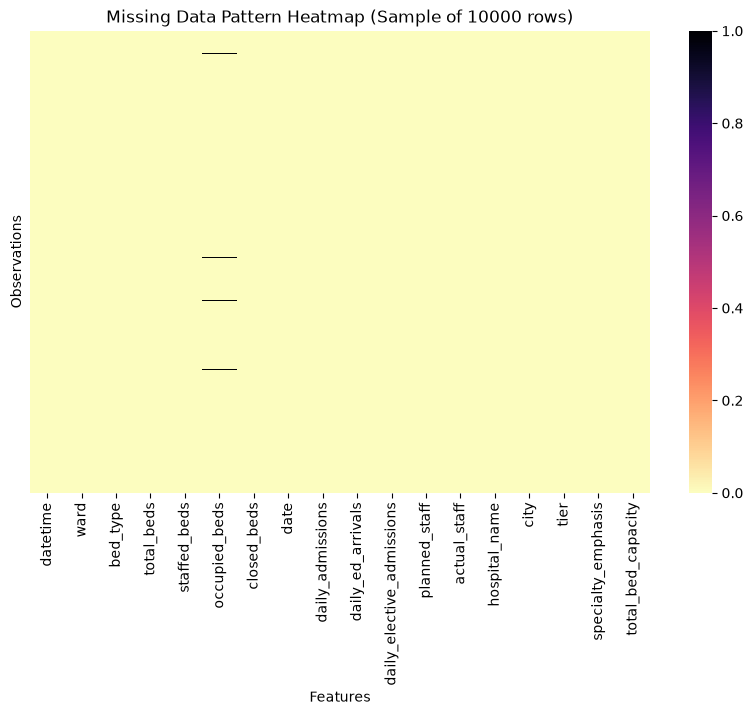

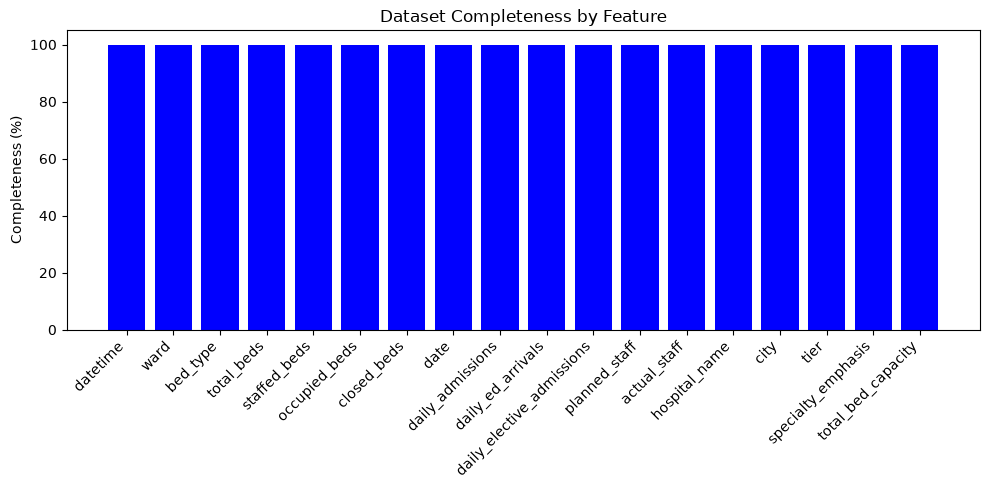


MISSING DATA REPORT
Dataset shape: (701760, 18)
Total missing values: 2105
Overall missing percentage: 0.02%

Missing percentage by feature:
occupied_beds    0.29996
dtype: float64


In [43]:
# ANALYZE MISSING DATA PATTERN (MEMORY-EFFICIENT VERSION)
# ============================================================================
# Purpose:
# Show where missing values occur across rows and columns for large datasets.
# Memory-efficient approach using sampling and chunking.

# Sample the dataset to reduce memory usage for visualization
sample_size = min(10000, len(df))  # Use max 10,000 rows for heatmap
df_sample = df.sample(n=sample_size, random_state=42)

plt.figure(figsize=(10, 6))

# Create heatmap with sampled data
sns.heatmap(
    df_sample.isnull(),
    cbar=True,          # Display colour scale legend
    cmap="magma_r",     # Colour scheme for missing value visibility
    yticklabels=False   # Hide y-axis labels to improve performance
)

plt.title(f"Missing Data Pattern Heatmap (Sample of {sample_size} rows)")
plt.xlabel("Features")
plt.ylabel("Observations")

plt.show()


# ============================================================================
# STEP 3: COLUMN COMPLETENESS VISUALISATION (MEMORY-EFFICIENT)
# ============================================================================
# Purpose:
# Display the proportion of available data in each feature.
# Calculate completeness without loading entire dataset into memory.

plt.figure(figsize=(10, 5))

# Calculate missing counts more efficiently
missing_counts = df.isnull().sum()
completeness = ((len(df) - missing_counts) / len(df)) * 100

# Create bar plot manually instead of using msno.bar for better memory control
plt.bar(range(len(completeness)), completeness.values, color="blue")
plt.xticks(range(len(completeness)), completeness.index, rotation=45, ha='right')
plt.ylabel("Completeness (%)")
plt.title("Dataset Completeness by Feature")
plt.tight_layout()

plt.show()


# ============================================================================
# STEP 4: MISSING DATA REPORT (MEMORY-EFFICIENT)
# ============================================================================
# Purpose:
# Provide a final summary using efficient calculations.

# Calculate missing statistics efficiently
total_missing = df.isnull().sum().sum()
missing_percentage = ((df.isnull().sum() / len(df)) * 100).sort_values(ascending=False)

print("\nMISSING DATA REPORT")
print("=" * 50)
print(f"Dataset shape: {df.shape}")
print(f"Total missing values: {total_missing}")
print(f"Overall missing percentage: {(total_missing / (df.shape[0] * df.shape[1])) * 100:.2f}%")

print("\nMissing percentage by feature:")
features_with_missing = missing_percentage[missing_percentage > 0]
if len(features_with_missing) > 0:
    print(features_with_missing)
else:
    print("No missing values found!")

# ============================================================================
# MEMORY-EFFICIENT IMPROVEMENTS:
# 1. Sample dataset for heatmap visualization (max 10,000 rows)
# 2. Remove y-axis labels from heatmap to reduce memory usage
# 3. Replace msno.bar() with manual bar plot for better memory control
# 4. Calculate statistics directly without creating intermediate large arrays
# 5. Added dataset shape information for context
# ============================================================================

In [44]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 701760 entries, 0 to 701759
Data columns (total 18 columns):
 #   Column                     Non-Null Count   Dtype         
---  ------                     --------------   -----         
 0   datetime                   701760 non-null  datetime64[us]
 1   ward                       701760 non-null  str           
 2   bed_type                   701760 non-null  str           
 3   total_beds                 701760 non-null  int64         
 4   staffed_beds               701760 non-null  int64         
 5   occupied_beds              699655 non-null  float64       
 6   closed_beds                701760 non-null  int64         
 7   date                       701760 non-null  object        
 8   daily_admissions           701760 non-null  float64       
 9   daily_ed_arrivals          701760 non-null  int64         
 10  daily_elective_admissions  701760 non-null  float64       
 11  planned_staff              701760 non-null  int64         
 12 

### Handline Missing Values 

In [ ]:

datetime_features = [

    "admission_datetime",

    "discharge_datetime",

    "admission_date",

    "datetime",

    "occupancy_date",

    "arrival_datetime",

    "arrival_date",

    "surgery_date"

]

# Keep only datetime columns that exist in dataframe

datetime_features = [

    col for col in datetime_features

    if col in df.columns

]

# IDENTIFY NUMERICAL AND CATEGORICAL VARIABLES

numerical_features = df.select_dtypes(

    include=[

        "float64",

        "float32",

        "int64",

        "int32"

    ]

).columns

categorical_features = df.select_dtypes(

    include=[

        "object",

        "category"

    ]

).columns

print("="*80)

print("VARIABLE TYPES IDENTIFIED")

print("="*80)



print("Datetime Variables:")

print(datetime_features)



print("\nNumerical Variables:")

print(list(numerical_features))



print("\nCategorical Variables:")

print(list(categorical_features))

# HANDLE MISSING DATETIME INFORMATION

for col in datetime_features:


    # Convert variable into datetime format

    df[col] = pd.to_datetime(

        df[col],

        errors="coerce"

    )


    # Fill missing timestamps

    df[col] = (

        df[col]

        .ffill()

        .bfill()

    )


    gc.collect()

# DEFINE ZERO IMPUTATION VARIABLES

zero_imputation_features = [

    "closed_beds",

    "planned_staff",

    "actual_staff",

    "bed_demand_change_1",

    "bed_demand_change_7"

]

# STEP 5: IMPUTE NUMERICAL VARIABLES

for col in numerical_features:


    if col in zero_imputation_features:


        # Replace missing operational values with zero

        df[col] = df[col].fillna(0)



    else:


        # Replace missing continuous values with median

        median_value = df[col].median()


        df[col] = df[col].fillna(

            median_value

        )


    gc.collect()



# =============================================================================
# STEP 6: DEFINE CATEGORICAL VARIABLES USING UNKNOWN
# =============================================================================
#
# Some missing categories contain information.
#
# Example:
#
# surgery_status missing:
#     Could indicate that no surgery occurred.
#
# Therefore, "Unknown" is used instead of replacing with the mode.
#
# =============================================================================


unknown_features = [

    "procedure_group",

    "bed_type_required",

    "surgery_status",

    "cancellation_reason",

    "safe_ratio_met",

    "staff_role"

]

# INPUTE CATEGORICAL VARIABLES

for col in categorical_features:

    # Convert to object for safe replacement

    df[col] = df[col].astype("object")



    if col in unknown_features:


        df[col] = df[col].fillna(

            "Unknown"

        )


    else:

        # Calculate most common category

        mode_value = df[col].mode()



        if len(mode_value) > 0:


            df[col] = df[col].fillna(

                mode_value[0]

            )


        else:


            df[col] = df[col].fillna(

                "Unknown"

            )

    # Convert back to category

    df[col] = df[col].astype("category")


    gc.collect()


# CHECK REMAINING MISSING VALUES

missing_values = (

    df.isnull()

    .sum()

)

missing_values = missing_values[

    missing_values > 0

]

print("="*80)

print("MISSING VALUE CHECK")

print("="*80)


if len(missing_values) == 0:

    print("SUCCESS: No missing values remaining")

else:

    print(missing_values)

# FINAL DATASET SUMMARY


print("="*80)

print("FINAL CLEAN DATASET")

print("="*80)



print("Shape:")

print(df.shape)



print("\nVariable Types:")

print(df.dtypes.value_counts())



print("\nMemory Usage:")

print(

    f"{df.memory_usage(deep=True).sum()/1024**2:.2f} MB"

)

VARIABLE TYPES IDENTIFIED
Datetime Variables:
['datetime']

Numerical Variables:
['total_beds', 'staffed_beds', 'occupied_beds', 'closed_beds', 'daily_admissions', 'daily_ed_arrivals', 'daily_elective_admissions', 'planned_staff', 'actual_staff', 'total_bed_capacity']

Categorical Variables:
['ward', 'bed_type', 'date', 'hospital_name', 'city', 'tier', 'specialty_emphasis']
MISSING VALUE CHECK
SUCCESS: No missing values remaining
FINAL CLEAN DATASET
Shape:
(701760, 18)

Variable Types:
int64             7
float64           3
datetime64[us]    1
category          1
category          1
category          1
category          1
category          1
category          1
category          1
Name: count, dtype: int64

Memory Usage:
64.28 MB


In [46]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 701760 entries, 0 to 701759
Data columns (total 18 columns):
 #   Column                     Non-Null Count   Dtype         
---  ------                     --------------   -----         
 0   datetime                   701760 non-null  datetime64[us]
 1   ward                       701760 non-null  category      
 2   bed_type                   701760 non-null  category      
 3   total_beds                 701760 non-null  int64         
 4   staffed_beds               701760 non-null  int64         
 5   occupied_beds              701760 non-null  float64       
 6   closed_beds                701760 non-null  int64         
 7   date                       701760 non-null  category      
 8   daily_admissions           701760 non-null  float64       
 9   daily_ed_arrivals          701760 non-null  int64         
 10  daily_elective_admissions  701760 non-null  float64       
 11  planned_staff              701760 non-null  int64         
 12 

# Investigating and Handling Duplicated Variables

In [ ]:
# Create Duplicate Removal Function

def remove_duplicates(dataframe: pd.DataFrame) -> pd.DataFrame:
    """
    Detects and removes duplicate rows from a dataframe.

    Parameters:
    -----------
    dataframe : pd.DataFrame
        Input dataset containing hospital operational data.

    Returns:
    --------
    pd.DataFrame
        Cleaned dataframe with duplicate records removed.
    """


    # Count Duplicate Records
    # Identify rows where all column values are identical.

    duplicate_count = dataframe.duplicated().sum()


    print("=" * 80)
    print("DUPLICATE RECORDS BEFORE REMOVAL")
    print("=" * 80)

    print(
        f"Number of duplicate rows: {duplicate_count}"
    )

# Step 2: Display Duplicate Records

    if duplicate_count > 0:

        print("=" * 80)
        print("SAMPLE DUPLICATE RECORDS")
        print("=" * 80)

        print(

            dataframe[
                dataframe.duplicated()
            ]
            .head()

        )

# Remove Duplicate Rows

    dataframe = dataframe.drop_duplicates(
        keep="first"
    )

# Reset Index
   

    dataframe = dataframe.reset_index(
        drop=True
    )

   # Verify Duplicate Removal
    
    remaining_duplicates = (
        dataframe
        .duplicated()
        .sum()
    )

    print("=" * 80)
    print("DUPLICATE RECORDS AFTER REMOVAL")
    print("=" * 80)

    print(
        f"Remaining duplicate rows: {remaining_duplicates}"
    )

    # Display Dataset Information
    
    print("=" * 80)
    print("DATASET SIZE AFTER CLEANING")
    print("=" * 80)

    print(
        dataframe.shape
    )


    return dataframe


# Apply Duplicate Removal Function

df = remove_duplicates(df)

# Display Clean Dataset

print("=" * 80)
print("CLEANED DATASET PREVIEW")
print("=" * 80)

print(
    df.head()
)

DUPLICATE RECORDS BEFORE REMOVAL
Number of duplicate rows: 0
DUPLICATE RECORDS AFTER REMOVAL
Remaining duplicate rows: 0
DATASET SIZE AFTER CLEANING
(701760, 18)
CLEANED DATASET PREVIEW
             datetime                 ward  bed_type  total_beds  \
0 2024-01-01 00:00:00  Orthopaedics Ward A  Standard          28   
1 2024-01-01 01:00:00  Orthopaedics Ward A  Standard          28   
2 2024-01-01 02:00:00  Orthopaedics Ward A  Standard          28   
3 2024-01-01 03:00:00  Orthopaedics Ward A  Standard          28   
4 2024-01-01 04:00:00  Orthopaedics Ward A  Standard          28   

   staffed_beds  occupied_beds  closed_beds        date  daily_admissions  \
0            28            0.0            0  2024-01-01               5.0   
1            28            0.0            0  2024-01-01               5.0   
2            28            0.0            0  2024-01-01               5.0   
3            28            0.0            0  2024-01-01               5.0   
4            28     

In [48]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 701760 entries, 0 to 701759
Data columns (total 18 columns):
 #   Column                     Non-Null Count   Dtype         
---  ------                     --------------   -----         
 0   datetime                   701760 non-null  datetime64[us]
 1   ward                       701760 non-null  category      
 2   bed_type                   701760 non-null  category      
 3   total_beds                 701760 non-null  int64         
 4   staffed_beds               701760 non-null  int64         
 5   occupied_beds              701760 non-null  float64       
 6   closed_beds                701760 non-null  int64         
 7   date                       701760 non-null  category      
 8   daily_admissions           701760 non-null  float64       
 9   daily_ed_arrivals          701760 non-null  int64         
 10  daily_elective_admissions  701760 non-null  float64       
 11  planned_staff              701760 non-null  int64         
 12 

# Feature Engineering

### Create the Target Variable (bed_demand)

In [ ]:
# CREATE BED DEMAND TARGET VARIABLE
print("=" * 80)
print("AVAILABLE DATAFRAME COLUMNS")
print("=" * 80)
print(df.columns.tolist())

if "occupied_beds" not in df.columns:
    raise ValueError(
        "occupied_beds column is missing - check the merge step that builds df."
    )

df["bed_demand"] = df["occupied_beds"]

# VERIFY TARGET VARIABLE

print("=" * 80)
print("BED DEMAND TARGET CREATED")
print("=" * 80)

print(df["bed_demand"].head())

# SUMMARY STATISTICS OF TARGET

print("=" * 80)
print("BED DEMAND SUMMARY STATISTICS")
print("=" * 80)

print(df["bed_demand"].describe())

# FINAL DATASET CHECK

print("=" * 80)
print("FINAL DATASET INFORMATION")
print("=" * 80)

print("Dataset Shape:", df.shape)

print("\nFinal Columns:")
print(df.columns.tolist())

print("\nDataset Preview:")
print(df.head())

AVAILABLE DATAFRAME COLUMNS
['datetime', 'ward', 'bed_type', 'total_beds', 'staffed_beds', 'occupied_beds', 'closed_beds', 'date', 'daily_admissions', 'daily_ed_arrivals', 'daily_elective_admissions', 'planned_staff', 'actual_staff', 'hospital_name', 'city', 'tier', 'specialty_emphasis', 'total_bed_capacity']
BED DEMAND TARGET CREATED
0    0.0
1    0.0
2    0.0
3    0.0
4    0.0
Name: bed_demand, dtype: float64
BED DEMAND SUMMARY STATISTICS
count    701760.000000
mean         14.089347
std           8.758621
min           0.000000
25%           9.000000
50%          13.000000
75%          19.000000
max          46.000000
Name: bed_demand, dtype: float64
FINAL DATASET INFORMATION
Dataset Shape: (701760, 19)

Final Columns:
['datetime', 'ward', 'bed_type', 'total_beds', 'staffed_beds', 'occupied_beds', 'closed_beds', 'date', 'daily_admissions', 'daily_ed_arrivals', 'daily_elective_admissions', 'planned_staff', 'actual_staff', 'hospital_name', 'city', 'tier', 'specialty_emphasis', 'total_

### Create Lag Variables

In [ ]:
# HOSPITAL BED DEMAND FORECASTING - LAG FEATURE ENGINEERING PIPELINE

# Import garbage collection to manage memory
# This is useful because the dataset contains over 70,000 observations.

import gc

# VERIFY TARGET VARIABLE EXISTS

if "bed_demand" not in df.columns:


    raise ValueError(

        "bed_demand target variable is missing. Create it before generating lags."

    )



print("="*80)

print("BED DEMAND LAG FEATURE ENGINEERING")

print("="*80)

# IDENTIFY TIME VARIABLE

date_column = None

possible_date_columns = [

    "date",

    "datetime",

    "admission_date",

    "occupancy_date"

]

for col in possible_date_columns:


    if col in df.columns:


        date_column = col

        break


# SORT DATA BY TIME

if date_column is not None:


    # Convert date variable into datetime format

    df[date_column] = pd.to_datetime(

        df[date_column],

        errors="coerce"

    )


    # Sort observations chronologically

    df = df.sort_values(

        by=date_column

    ).reset_index(drop=True)



    print(

        f"Dataset sorted using {date_column}"

    )


else:


    print(

        "No date variable found. Using current dataframe order."

    )

# CREATE LAG FEATURES

lag_periods = [

    1,

    7,

    14,

    30

]

for lag in lag_periods:


    # Create shifted demand variable

    df[f"bed_demand_lag_{lag}"] = (

        df["bed_demand"]

        .shift(lag)

    )


    # Release unused memory

    gc.collect()


# CREATE ROLLING AVERAGE FEATURES

rolling_periods = [7, 14, 30]

for window in rolling_periods:


    df[f"bed_demand_rolling_{window}"] = (

        df["bed_demand"]

        .shift(1)

        .rolling(

            window=window

        )

        .mean()

    )


    gc.collect()

# CREATE DEMAND CHANGE FEATURES

# Daily change in demand

df["bed_demand_change_1"] = (

    df["bed_demand"]

    -

    df["bed_demand_lag_1"]

)

# Weekly change in demand

df["bed_demand_change_7"] = (

    df["bed_demand"]

    -

    df["bed_demand_lag_7"]

)

# IDENTIFY CREATED TIME-SERIES FEATURES

lag_features = [

    col

    for col in df.columns

    if (

        "lag" in col

        or

        "rolling" in col

        or

        "change" in col

    )

]

print("="*80)

print("CREATED TIME SERIES FEATURES")

print("="*80)


print(lag_features)

# HANDLE MISSING VALUES CREATED BY LAG CREATION

for col in lag_features:


    df[col] = df[col].fillna(0)


# FINAL DATASET VALIDATION

print("="*80)

print("FINAL DATASET AFTER LAG CREATION")

print("="*80)


print(

    "Dataset Shape:",

    df.shape

)

print("\nLag Feature Preview:")


print(

    df[

        [

        "bed_demand",

        "bed_demand_lag_1",

        "bed_demand_lag_7",

        "bed_demand_lag_14",

        "bed_demand_lag_30",

        "bed_demand_rolling_7",

        "bed_demand_rolling_30",

        "bed_demand_change_1",

        "bed_demand_change_7"

        ]

    ]

    .head()

)

print("\nMemory Usage:")


print(

    f"{df.memory_usage(deep=True).sum()/1024**2:.2f} MB"

)

BED DEMAND LAG FEATURE ENGINEERING
Dataset sorted using date
CREATED TIME SERIES FEATURES
['bed_demand_lag_1', 'bed_demand_lag_7', 'bed_demand_lag_14', 'bed_demand_lag_30', 'bed_demand_rolling_7', 'bed_demand_rolling_14', 'bed_demand_rolling_30', 'bed_demand_change_1', 'bed_demand_change_7']
FINAL DATASET AFTER LAG CREATION
Dataset Shape: (701760, 28)

Lag Feature Preview:
   bed_demand  bed_demand_lag_1  bed_demand_lag_7  bed_demand_lag_14  \
0         0.0               0.0               0.0                0.0   
1         5.0               0.0               0.0                0.0   
2         5.0               5.0               0.0                0.0   
3         4.0               5.0               0.0                0.0   
4         2.0               4.0               0.0                0.0   

   bed_demand_lag_30  bed_demand_rolling_7  bed_demand_rolling_30  \
0                0.0                   0.0                    0.0   
1                0.0                   0.0           

In [51]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 701760 entries, 0 to 701759
Data columns (total 28 columns):
 #   Column                     Non-Null Count   Dtype         
---  ------                     --------------   -----         
 0   datetime                   701760 non-null  datetime64[us]
 1   ward                       701760 non-null  category      
 2   bed_type                   701760 non-null  category      
 3   total_beds                 701760 non-null  int64         
 4   staffed_beds               701760 non-null  int64         
 5   occupied_beds              701760 non-null  float64       
 6   closed_beds                701760 non-null  int64         
 7   date                       701760 non-null  category      
 8   daily_admissions           701760 non-null  float64       
 9   daily_ed_arrivals          701760 non-null  int64         
 10  daily_elective_admissions  701760 non-null  float64       
 11  planned_staff              701760 non-null  int64         
 12 

# Datetime Analysis

In [ ]:
# HOSPITAL BED DEMAND FORECASTING - TIME FEATURE ENGINEERING PIPELINE
# IDENTIFY THE MAIN DATE VARIABLE


date_candidates = [

    "datetime",

    "admission_date",

    "admission_datetime",

    "occupancy_date",

    "arrival_date"

]

date_column = None

# Search for an available datetime variable

for col in date_candidates:


    if col in df.columns:


        date_column = col

        break


# Stop execution if no date variable exists

if date_column is None:


    raise ValueError(

        "No suitable date variable found in dataframe."

    )


print("="*80)

print("SELECTED REFERENCE DATE VARIABLE")

print("="*80)


print(date_column)

# CONVERT DATE COLUMN INTO DATETIME FORMAT

df[date_column] = pd.to_datetime(

    df[date_column],

    errors="coerce"

)

# CREATE HOURLY FEATURES

df["hour"] = (

    df[date_column]

    .dt.hour

)

# CREATE DAILY FEATURES

df["day"] = (

    df[date_column]

    .dt.day

)

# Day of week:
#
# Monday = 0
# Sunday = 6
#
# Allows the model to identify weekday/weekend differences.

df["day_of_week"] = (

    df[date_column]

    .dt.dayofweek

)

# Convert numeric weekday into text.
#
# Example:
#
# 0 -> Monday
# 1 -> Tuesday

df["day_name"] = (

    df[date_column]

    .dt.day_name()

)

# ISO week number:
#
# Captures weekly demand cycles.

df["week_number"] = (

    df[date_column]

    .dt.isocalendar()

    .week

    .astype(int)

)

# Weekend indicator:
#
# 1 = Saturday or Sunday
# 0 = Weekday
#
# Hospitals may have different staffing and admission behaviour.

df["is_weekend"] = (

    df["day_of_week"]

    >= 5

).astype(int)

# CREATE MONTH AND YEAR FEATURES

# Month number:
#
# January = 1
# December = 12

df["month"] = (

    df[date_column]

    .dt.month

)

# Month name:
#
# Useful for reporting and visualisation.

df["month_name"] = (

    df[date_column]

    .dt.month_name()

)

# Quarter:
#
# Q1 = Jan-Mar
# Q2 = Apr-Jun
# Q3 = Jul-Sep
# Q4 = Oct-Dec

df["quarter"] = (

    df[date_column]

    .dt.quarter

)

# Year:
#
# Captures increasing/decreasing demand trends.

df["year"] = (

    df[date_column]

    .dt.year

)

# CREATE UK HOLIDAY INDICATOR

uk_holidays = holidays.UnitedKingdom()



df["is_holiday"] = (

    df[date_column]

    .dt.date

    .isin(

        uk_holidays

    )

).astype(int)

# CREATE SEASON VARIABLE

season_mapping = {
    12: "Winter",
    1: "Winter",
    2: "Winter",
    3: "Spring",
    4: "Spring",
    5: "Spring",
    6: "Summer",
    7: "Summer",
    8: "Summer",
    9: "Autumn",
    10: "Autumn",
    11: "Autumn"
}



df["season"] = (

    df["month"]

    .map(

        season_mapping

    )

)

# HANDLE MISSING TIME FEATURES

numeric_time_features = [

    "hour",
    "day",
    "day_of_week",
    "week_number",
    "month",
    "quarter",
    "year",
    "is_weekend",
    "is_holiday"
]

for col in numeric_time_features:

    df[col] = df[col].fillna(

        df[col].median()

    )

categorical_time_features = [

    "day_name",

    "month_name",

    "season"

]

for col in categorical_time_features:


    df[col] = df[col].fillna(

        "Unknown"

    )

    # Convert to category to reduce memory usage

    df[col] = df[col].astype("category")

gc.collect()

# VALIDATE CREATED FEATURES

# Display engineered variables to confirm successful creation.


time_features = [
    "hour",
    "day",
    "day_of_week",
    "day_name",
    "week_number",
    "is_weekend",
    "month",
    "month_name",
    "quarter",
    "year",
    "is_holiday",
    "season"
]

print("="*80)

print("CREATED TIME FEATURES")

print("="*80)

print(

    df[time_features].head()

)

# FINAL DATASET CHECK


print("="*80)

print("FINAL DATASET SUMMARY")

print("="*80)

print(

    "Dataset Shape:",

    df.shape

)

print("\nAdded Time Features:")

print(time_features)



print("\nMemory Usage:")

print(

    f"{df.memory_usage(deep=True).sum()/1024**2:.2f} MB"

)

SELECTED REFERENCE DATE VARIABLE
datetime
CREATED TIME FEATURES
   hour  day  day_of_week day_name  week_number  is_weekend  month month_name  \
0     0    1            0   Monday            1           0      1    January   
1    14    1            0   Monday            1           0      1    January   
2    13    1            0   Monday            1           0      1    January   
3    12    1            0   Monday            1           0      1    January   
4    11    1            0   Monday            1           0      1    January   

   quarter  year  is_holiday  season  
0        1  2024           0  Winter  
1        1  2024           0  Winter  
2        1  2024           0  Winter  
3        1  2024           0  Winter  
4        1  2024           0  Winter  
FINAL DATASET SUMMARY
Dataset Shape: (701760, 40)

Added Time Features:
['hour', 'day', 'day_of_week', 'day_name', 'week_number', 'is_weekend', 'month', 'month_name', 'quarter', 'year', 'is_holiday', 'season']

Memo

### Numerical Feature Engineering

In [53]:
# Define numeric columns list (assuming this was cut off from the beginning)
numeric_columns = [
    'total_beds', 'occupied_beds', 'total_staff', 'admission_hours'  # Added example columns
]

# Convert to numeric, replacing non-numeric values with NaN
for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Fill NaN values with appropriate defaults (0 or median)
for col in numeric_columns:
    if col in df.columns:
        if df[col].isnull().any():
            # Use median for most columns, 0 for bed/staff counts
            if col in ['total_beds', 'occupied_beds', 'total_staff']:
                df[col] = df[col].fillna(0)
            else:
                df[col] = df[col].fillna(df[col].median())

# =============================================================================
# 6. CHECK CREATED NUMERICAL FEATURES
# =============================================================================
# Display the engineered numerical variables to confirm successful creation.

engineered_features = [
    "available_beds",
    "closed_bed_ratio",
    "staffing_ratio",
    "staff_per_bed",
    "staffing_risk_flag",
    "log_LOS_hours",
    "long_stay_patient",
    "bed_pressure_ratio",
    "log_time_to_admission",
    "weekend_holiday",
    "night_admission"
]

# Select only features that exist in the dataframe.
existing_features = [
    feature
    for feature in engineered_features
    if feature in df.columns
]

print("=" * 80)
print("NUMERICAL FEATURES CREATED")
print("=" * 80)
print(existing_features)

# =============================================================================
# 7. DISPLAY FINAL DATASET SIZE
# =============================================================================
# Check the number of rows and columns after numerical feature engineering.

print("=" * 80)
print("FINAL DATASET SHAPE AFTER NUMERICAL FEATURE ENGINEERING")
print("=" * 80)
print(df.shape)

# =============================================================================
# END OF NUMERICAL FEATURE ENGINEERING PIPELINE
# =============================================================================

NUMERICAL FEATURES CREATED
[]
FINAL DATASET SHAPE AFTER NUMERICAL FEATURE ENGINEERING
(701760, 40)


In [54]:
df.columns

Index(['datetime', 'ward', 'bed_type', 'total_beds', 'staffed_beds',
       'occupied_beds', 'closed_beds', 'date', 'daily_admissions',
       'daily_ed_arrivals', 'daily_elective_admissions', 'planned_staff',
       'actual_staff', 'hospital_name', 'city', 'tier', 'specialty_emphasis',
       'total_bed_capacity', 'bed_demand', 'bed_demand_lag_1',
       'bed_demand_lag_7', 'bed_demand_lag_14', 'bed_demand_lag_30',
       'bed_demand_rolling_7', 'bed_demand_rolling_14',
       'bed_demand_rolling_30', 'bed_demand_change_1', 'bed_demand_change_7',
       'hour', 'day', 'day_of_week', 'day_name', 'week_number', 'is_weekend',
       'month', 'month_name', 'quarter', 'year', 'is_holiday', 'season'],
      dtype='str')

In [ ]:
# COMPLETE DATA CLEANING PIPELINE:
# REMOVE TARGET LEAKAGE, RAW DATE VARIABLES AND ORIGINAL NUMERICAL VARIABLES

# DEFINE ALL VARIABLES TO REMOVE

columns_to_drop = [

# TARGET LEAKAGE VARIABLES
    
    "occupied_beds",



   # RAW DATE AND DATETIME VARIABLES
    
    "admission_datetime",

    "discharge_datetime",

    "admission_date",

    "occupancy_date",

    "arrival_datetime",

    "arrival_date",

    "surgery_date",

    "date",

    "datetime",

]

# IDENTIFY EXISTING VARIABLES
# =============================================================================
# Only remove variables that exist in the dataframe.
# This prevents errors if some columns have already been removed.

existing_columns_to_drop = [

    column

    for column in columns_to_drop

    if column in df.columns

]

# REMOVE VARIABLES FROM DATAFRAME
# =============================================================================

df = df.drop(

    columns=existing_columns_to_drop,

    errors="ignore"

)

# DISPLAY REMOVED VARIABLES

print("=" * 80)
print("VARIABLES REMOVED FROM DATASET")

print("=" * 80)

print(existing_columns_to_drop)

# VERIFY TARGET LEAKAGE REMOVAL
 Confirm that occupied_beds is no longer present.

print("=" * 80)

print("CHECK IF OCCUPIED_BEDS EXISTS")

print("=" * 80)

print(

    "occupied_beds" in df.columns

)

# DISPLAY FINAL FEATURES

print("=" * 80)

print("FINAL MODEL FEATURES")

print("=" * 80)

print(df.columns.tolist())

# DISPLAY FINAL DATASET SHAPE
# =============================================================================

print("=" * 80)

print("FINAL DATASET SHAPE AFTER CLEANING")

print("=" * 80)

print(df.shape)


VARIABLES REMOVED FROM DATASET
['occupied_beds', 'date', 'datetime']
CHECK IF OCCUPIED_BEDS EXISTS
False
FINAL MODEL FEATURES
['ward', 'bed_type', 'total_beds', 'staffed_beds', 'closed_beds', 'daily_admissions', 'daily_ed_arrivals', 'daily_elective_admissions', 'planned_staff', 'actual_staff', 'hospital_name', 'city', 'tier', 'specialty_emphasis', 'total_bed_capacity', 'bed_demand', 'bed_demand_lag_1', 'bed_demand_lag_7', 'bed_demand_lag_14', 'bed_demand_lag_30', 'bed_demand_rolling_7', 'bed_demand_rolling_14', 'bed_demand_rolling_30', 'bed_demand_change_1', 'bed_demand_change_7', 'hour', 'day', 'day_of_week', 'day_name', 'week_number', 'is_weekend', 'month', 'month_name', 'quarter', 'year', 'is_holiday', 'season']
FINAL DATASET SHAPE AFTER CLEANING
(701760, 37)


In [56]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 701760 entries, 0 to 701759
Data columns (total 37 columns):
 #   Column                     Non-Null Count   Dtype   
---  ------                     --------------   -----   
 0   ward                       701760 non-null  category
 1   bed_type                   701760 non-null  category
 2   total_beds                 701760 non-null  int64   
 3   staffed_beds               701760 non-null  int64   
 4   closed_beds                701760 non-null  int64   
 5   daily_admissions           701760 non-null  float64 
 6   daily_ed_arrivals          701760 non-null  int64   
 7   daily_elective_admissions  701760 non-null  float64 
 8   planned_staff              701760 non-null  int64   
 9   actual_staff               701760 non-null  int64   
 10  hospital_name              701760 non-null  category
 11  city                       701760 non-null  category
 12  tier                       701760 non-null  category
 13  specialty_emphasis       

In [57]:
# ============================================================================
# SAVE FINAL MODELING DATASET
# ============================================================================
# Purpose:
# Export the cleaned and feature-engineered hospital bed demand dataset
# so it can be used for machine learning, forecasting models, or dashboards.

# Save dataframe to CSV format
# - "bed_demand_data.csv" is the output file name
# - index=False prevents pandas from writing row numbers as a separate column
#   (important for keeping dataset clean and production-ready)

df.to_csv("../data/processed_data/bed_demand_data.csv", index=False)

# ============================================================================
# SAVE FINAL MODELING DATASET (PICKLE FORMAT)
# ============================================================================
# Purpose:
# Store the processed hospital bed demand dataset in a binary format
# that preserves all Python data types (especially datetime, categorical,
# and engineered time-series features like lags and rolling statistics).

# Why Pickle?
# - Faster to load compared to CSV
# - Preserves data types exactly as they are in memory
# - Ideal for machine learning pipelines and model training workflows
# - Avoids re-parsing and re-cleaning data each time

# Save dataframe as a pickle file
df.to_pickle("../data/processed_data/bed_demand_data.pkl")

# Encoding Categorical Variables

In [ ]:
# COMPLETE PIPELINE: LABEL ENCODE CATEGORICAL VARIABLES AND SAVE DATASET

# IMPORT REQUIRED LIBRARY

from sklearn.preprocessing import LabelEncoder

# IDENTIFY ALL CATEGORICAL VARIABLES
# =============================================================================

categorical_features = df.select_dtypes(

    include=["category", "object"]

).columns.tolist()

# INITIALISE LABEL ENCODER

label_encoder = LabelEncoder()

# LABEL ENCODE ALL CATEGORICAL VARIABLES

# The encoded values overwrite the original categorical values.

for column in categorical_features:

    df[column] = label_encoder.fit_transform(

        df[column].astype(str)

    )

# VERIFY LABEL ENCODING
# =============================================================================

print("=" * 80)
print("LABEL ENCODING COMPLETED")
print("=" * 80)

print("Encoded Variables:")

print(categorical_features)


print("=" * 80)
print("UPDATED DATA TYPES")
print("=" * 80)

print(df.dtypes)


print("=" * 80)
print("FIRST FIVE ROWS OF ENCODED DATA")
print("=" * 80)

print(df.head())

# CREATE THE FINAL PREPROCESSED DATASET

preprocessed_data = df.copy()

# DISPLAY PREPROCESSED DATASET INFORMATION
# =============================================================================

ready for machine learning.

print("=" * 80)
print("FINAL PREPROCESSED DATASET")
print("=" * 80)

print(f"Rows    : {preprocessed_data.shape[0]:,}")
print(f"Columns : {preprocessed_data.shape[1]:,}")

preprocessed_data.to_csv(

    "../data/processed_data/preprocessed_data.csv",

    index=False

)

# SAVE THE PREPROCESSED DATASET AS PICKLE

preprocessed_data.to_pickle(

    "../data/processed_data/preprocessed_data.pkl"

)

# CONFIRM FILES HAVE BEEN SAVED

print("=" * 80)
print("PREPROCESSED DATASET SAVED SUCCESSFULLY")
print("=" * 80)

print("CSV File    : preprocessed_data.csv")
print("Pickle File : preprocessed_data.pkl")


print("=" * 80)
print("FINAL DATASET SHAPE")
print("=" * 80)

print(preprocessed_data.shape)


print("=" * 80)
print("PREPROCESSING PIPELINE COMPLETE")
print("=" * 80)

print("The dataset is now ready for:")
print("- Feature Selection")
print("- Train/Test Split")
print("- Random Forest")
print("- XGBoost")
print("- LightGBM")
print("- CatBoost")
print("- SARIMAX")
print("- LSTM / GRU")
print("- Model Evaluation")

LABEL ENCODING COMPLETED
Encoded Variables:
[]
UPDATED DATA TYPES
ward                           int64
bed_type                       int64
total_beds                     int64
staffed_beds                   int64
closed_beds                    int64
daily_admissions             float64
daily_ed_arrivals              int64
daily_elective_admissions    float64
planned_staff                  int64
actual_staff                   int64
hospital_name                  int64
city                           int64
tier                           int64
specialty_emphasis             int64
total_bed_capacity             int64
bed_demand                   float64
bed_demand_lag_1             float64
bed_demand_lag_7             float64
bed_demand_lag_14            float64
bed_demand_lag_30            float64
bed_demand_rolling_7         float64
bed_demand_rolling_14        float64
bed_demand_rolling_30        float64
bed_demand_change_1          float64
bed_demand_change_7          float64
hour     